In [1]:
%matplotlib inline

import itertools
import json
import math
import random
import string
from collections.abc import Iterable

import geopandas as gpd
import matplotlib.pyplot as plt
import shapely.geometry as geom

from weavingspace import TileUnit, Tiling, tiling_utils

num = int | float

In [2]:
# read tile specs from supplied JSON
# note that there are definitely duplicates
with open("tiles.json") as file:
  Symbols1 = json.load(file)
with open("tiles-2.json") as file:
  Symbols2 = json.load(file)
Symbols = Symbols1 | Symbols2

In [3]:
"""Manually transcoded from javascript implementation of

JE Soto Sánchez, T Weyrich, LH de Figueiredo, A Medeiros e Sá. 2021. An integer
representation for periodic tilings of the plane with regular polygons Computer
& Graphics 95 69-80. doi: 10.1016/j.cag.2021.01.007

available at https://chequesoto.info/tiling/. Variable names have been
python-ised and in many cases changed to more closely reflect weavingspace's
model of tiling and what we're doing here!
"""

EPS = 1e-4
SQRT3 = math.sqrt(3) / 2

# unit vectors in four 30º directions in the first quadrant
X_BASE = 1, SQRT3, 0.5, 0
Y_BASE = 0, 0.5, SQRT3, 1

def _negate(it:Iterable[num]) -> tuple[num]:
  return tuple(-x for x in it)
 
def _negate_and_extend(it:Iterable[Iterable[num]]) -> tuple[tuple[num]]:
  return (*it, *(_negate(x) for x in it))

def _sum(*a:Iterable[num]) -> tuple[num]:
  return tuple(sum(_) for _ in zip(*a, strict = True))

def _product(*a:Iterable[num]) -> tuple[num]:
  if isinstance(a[0], Iterable):
    return tuple(math.prod(_) for _ in zip(*a, strict = True))
  return tuple(a[0] * math.prod(_) for _ in zip(*a[1:], strict = True))

# Coordinates of the twelve 30º spaced unit vectors expressed as combinations
# of the 0, 30, 60, and 90º unit vectors (described in the Soto Sanchéz paper as
# the 12th root of unity in the complex plane). The first four are the basis,
# all others are linear combinations of these four.
BASE_COORDS = [
  ( 1,  0,  0,  0),  # ω^0, i.e., to right along x-axis
  ( 0,  1,  0,  0),  # ω^1, up to right at 30º
  ( 0,  0,  1,  0),  # ω^2, up to right at 60º
  ( 0,  0,  0,  1),  # ω^3, up along y-axis, 90º... and so on
  (-1,  0,  1,  0),  # e.g, this one is left + up to right at 60º, or -ω^0 + ω^2
  ( 0, -1,  0,  1),
]
# 180º rotations are negative coords
BASE_COORDS = _negate_and_extend(BASE_COORDS)

# offsets of centroids of duals from a vertex expressed in BASE_COORDS (times 6)
# indexed by number of sides of polygon, and orientation of incident edge
# so CENTROID_OFFSETs[4][2] is offset for centroid of a square for edge at 60º
# 6 multiplier keeps all numbers integers, allowing precise maths - we divide
# through by 6 as needed when actual coordinates are requested
CENTROID_OFFSETS = {
  3:  ((2, 0, 2, 0), (0, 2, 0, 2), (-2, 0, 4, 0), 
       (0, -2, 0, 4), (-4, 0, 2, 0), (0, -4, 0, 2)),
  4:  ((3, 0, 0, 3), (-3, 3, 3, 0), (0, -3, 3, 3),
       (-3, 0, 0, 3), (-3, -3, 3, 0), (0, -3, -3, 3)),
  6:  ((0, 0, 6, 0), (0, 0, 0, 6), (-6, 0, 6, 0),
       (0, -6, 0, 6), (-6, 0, 0, 0), (0, -6, 0, 0)),
  12: ((0, 0, 6, 6), (-6, 0, 6, 6), (-6, -6, 6, 6),
       (-6, -6, 0, 6), (-6, -6, 0, 0), (0, -6, -6, 0)),
}
# 180º rotations are negative coords
CENTROID_OFFSETS = {
  k: _negate_and_extend(v) for k, v in CENTROID_OFFSETS.items()
}

In [4]:
def change_base(a:Iterable[num],
                t1:Iterable[num],
                t2:Iterable[num]) -> Iterable[num]:
  """Transform supplied vector to specified basis.

  Args:
    a (Iterable[num]): vector to transform.
    t1 (Iterable[num]): first basis vector.
    t2 (Iterable[num]): second basis vector.

  Returns:
    Iterable[num]: transformed vector.

  """
  det = t1[0] * t2[1] - t1[1] * t2[0]
  d1 =   a[0] * t2[1] -  a[1] * t2[0]
  d2 =  t1[0] *  a[1] - t1[1] *  a[0]
  return d1 / det, d2 / det


def base_to_point(coords:Iterable[int]) -> tuple[float]:
  """Convert supplied integer coordinates to point in Euclidean space.

  Args:
    coords (Iterable[int]): 4-tuple of integer coordinates.

  Returns:
    tuple[float]: corresponding tuple of coordinates in Euclidean space.

  """
  return sum(_product(coords, X_BASE)), \
         sum(_product(coords, Y_BASE))


def get_vertices(points:Iterable[Iterable[int]],
                 t1:Iterable[int],
                 t2:Iterable[int]) -> tuple[int]:
  """Get points in fundamental unit and neighbouring fundamental units.

  Applies translation vectors to augment list of supplied points with matching
  points in each translation vector direction, and also one move diagonally,
  i.e. at (0, 0), (0, 1), (1, 0), and (1, 1).

  Args:
    points (Iterable[int]): points in base tile.
    t1 (Iterable[int]): first translation vector.
    t2 (Iterable[int]): second translation vector.

  Returns:
    tuple[int]: extended tuple of points in base tile and matching points
      offset by translation vectors.

  """
  patch = []
  for k1 in range(2):
    for k2 in range(2):
      for point in points:
        patch.append(_sum(point, _product(k1, t1), _product(k2, t2)))
  return patch


def get_patch_hash(points:Iterable[Iterable[int]],
                   t1:Iterable[int],
                   t2:Iterable[int],
                   n0:int = -1, n1:int = 2) -> dict[tuple[int]:int]:
  """Get dictionary with integer tuple keys for all points in local patch.

  Args:
    points (Iterable[int]): points in base tile.
    t1 (Iterable[int]): first translation vector.
    t2 (Iterable[int]): second translation vector.
    n0 (int): lower bound on offset tiles to check in patch.
    n1 (int): upper bound on offset tiles to check in patch.

  Returns:
    dict[tuple[int]:int]: a dictionary keyed by base tile integer coordinates
      of all points and their matching points in the surrounding patch.

  """
  patch = {}
  # note both loops n0 to n1 _inclusive_
  for k1 in range(n0, n1 + 1):
    for k2 in range(n0, n1 + 1):
      for point in points:
        # coords are ints so are tuple is a safe dictionary key
        hashcode = _sum(point, _product(k1, t1), _product(k2, t2))
        patch[hashcode] = 1
  return patch


def get_star(v:Iterable[int], patch:Iterable[Iterable[int]]) -> list[int]:
  """Return direction in which supplied vertex has neighhours in patch.

  Args:
    v (Iterable[int]): vertex to find neighbours of.
    patch (Iterable[Iterable[int]]): collection of candidate neighbors.

  Returns:
    list[int]: list of directions in which vertex has neighbouring vertices.

  """
  star = []
  for k in range(12):
    candidate = _sum(v, BASE_COORDS[k])
    if candidate in patch:
      star.append(k)
  return star


def omega_to_poly(angle:int) -> int:
  """Return polygon degree based on angle supplied as multiple of 30º.

  Args:
    angle (int): number of 30º turns.

  Returns:
    int: number of sides of regular polygon.

  """
  k = abs(angle)
  n = 0
  return (3 if k == 2
    else  4 if k == 3
    else  6 if k == 4
    else 12 if k == 5
    else omega_to_poly(12 - k) if k >= 6
    else None)
  return n


def get_face(vertex:Iterable[int],
             heading:int,
             n_sides:int) -> tuple[tuple[int],list[tuple[int]]]:
  """Return polygon at vertex with given start heading and number of sides.

  Args:
    vertex (Iterable[int]): start vertex.
    heading (int): heading expressed as number of 30º increments from 0º.
    n_sides (int): number of sides of required polygon.

  Returns:
    list[tuple[int]]: corners of required polygon.

  """
  J = math.floor(12 / n_sides)
  face = [vertex]
  for angle in range(0, 12, J):
    p = _sum(face[-1], BASE_COORDS[(heading + angle) % 12])
    face.append(p)
  return face[:-1]


def star_to_faces(star:Iterable[int],
                  vertex:Iterable[int]) -> list[tuple[int]]:
  """Return centroids and polygons incident on this vertex.

  Args:
    star (Iterable[int]): directions in 30º increments of edges at this vertex.
    vertex (Iterable[int]): vertex coordinates.

  Returns:
    list[list[tuple[int]]]]: list of list of vertices of tiles incident at this
      vertex.

  """
  faces = []
  for left, right in zip(star, [*star[1:], star[0]], strict = True):
    n = omega_to_poly((right - left) % 12)
    if n > 0:
      face = get_face(vertex, left, n)
      faces.append(face)
  return faces


def get_dual_face(star:Iterable[int],
                  centre:Iterable[int]) -> Iterable[Iterable[int]]:
  """Return dual polygon centred on supplied centre based on vertex star.

  Args:
    star (Iterable[int]): vertex on which this dual face is based.
    centre (Iterable[int]): coordinates of vertex.

  Returns:
    Iterable[Iterable[int]]: coordinates (times 6) of dual polygon.

  """
  corners = []
  for left, right in zip(star, [*star[1:], star[0]], strict = True):
    n = omega_to_poly((right - left) % 12)
    if n > 0:
      corners.append(_sum(_product(6, centre), CENTROID_OFFSETS[n][left]))
  return corners


def is_in_region(p:Iterable[int], t1:list[int], t2:list[int]) -> bool:
  """Check if point p is in the region defined by two translation vectors.

  Test is conducted by transforming point into the basis space of the vectors,
  and checking if it falls in the unit square in the transformed coordinate
  space.

  Args:
    p (Iterable[int]): point to check.
    t1: list[int]: first translation vector.
    t2: list[int]: second translation vector.

  Returns:
    bool: True if the point lies in the space, False if not.

  """
  U = change_base(base_to_point(p), base_to_point(t1), base_to_point(t2))
  return ((U[0] >= -EPS) and (U[0] < 1 - EPS) and 
          (U[1] >= -EPS) and (U[1] < 1 - EPS))


def mesh_build(tile):
  mesh1 = ArchMesh()
  if tile not in ["t1002", "J"]:
    ts1 = Symbols[tile]["T1"]
    ts2 = Symbols[tile]["T2"]
    seed = Symbols[tile]["Seed"]
    vertices = get_vertices(seed, ts1, ts2)
    patch = get_patch_hash(seed, ts1, ts2)
    tiles = [] # tile polygons
    centroids_hash = {} # to not triple polygons - each incident on 3 vertices
    dual_tiles = []
    for vertex in vertices:
      star = get_star(vertex, patch)
      these_faces = star_to_faces(star, vertex)
      for face in these_faces:
        centroid = tuple(int(6 * p / len(face)) for p in _sum(*face))
        # times-6 factor keeps coords as integers, which we enforce to stop
        # floating point errors creeping in, and so that centroid can be safely
        # used as dictionary key
        if centroid not in centroids_hash and \
            is_in_region(_product(1/6, centroid), ts1, ts2):
          centroids_hash[centroid] = 1
          tiles.append(face)
      if is_in_region(vertex, ts1, ts2):
        dual_tiles.append(get_dual_face(star, vertex))
    mesh1.tvec1 = ts1
    mesh1.tvec2 = ts2
    mesh1.tiles = tiles
    mesh1.dual_faces = dual_tiles
  else:
    # 4.8.8 vertex only occurs in one regular tiling and does not align with
    # 30º lattice - so hard code its results (we could also remove it from
    # the data!
    ct = math.sqrt(2) / 2
    mesh1.tvec1 = [1 + ct, 0, 0, 1 + ct]
    mesh1.tvec2 = [2 + 2*ct, 0, 0, 0]
    E   = [1, 0, 0, 0]
    NE  = [ct, 0, 0, ct]
    N  = [0, 0, 0, 1]
    SE = [ct, 0, 0, -ct]
    mesh1.tiles = [
      [[0, 0, 0, 0], E, _sum(E, N), N],
      [E, _sum(E, N), _sum(E, N, NE), _sum(E, N, NE, E),
       _sum(E, N, NE, E, SE), _sum(E, SE, E, NE), _sum(E, SE, E), _sum(E, SE)]]
    mesh1.dual_faces = [
      [[3, 0, 0, 3], [ 9 + 6*ct, 0, 0,         3], [ 3,        0, 0,  9 + 6*ct]],
      [[3, 0, 0, 3], [ 3,        0, 0,  9 + 6*ct], [-3 - 6*ct, 0, 0,         3]],
      [[3, 0, 0, 3], [ 3,        0, 0, -3 - 6*ct], [ 9 + 6*ct, 0, 0,         3]],
      [[3, 0, 0, 3], [-3 - 6*ct, 0, 0,         3], [ 3,        0, 0, -3 - 6*ct]],
    ]
  return mesh1


class ArchMesh:
  def __init__(self):
    self.tvec1 = []
    self.tvec2 = []
    self.tiles = []
    self.dual_faces = []


In [5]:
def get_tile(code, scale = 50, dual = False):
  mesh = mesh_build(code)
  n = len(mesh.tiles)
  if dual:
    polys = gpd.GeoSeries(
      [geom.Polygon([base_to_point(_product(1/6, xy)) for xy in dual])
                     for dual in mesh.dual_faces])
  else:
    polys = [geom.Polygon([base_to_point(xy)
             for xy in points]) for points in mesh.tiles]
  t = TileUnit()
  t.tiles = gpd.GeoDataFrame(
    geometry = gpd.GeoSeries(polys), crs = 3857,
    data = {"tile_id": tiling_utils.TILE_IDS[:len(polys)]} 
  )
  t.setup_vectors(base_to_point(mesh.tvec1), base_to_point(mesh.tvec2))
  t.prototile = t.get_prototile_from_vectors()
  t._setup_regularised_prototile(override = True)
  return t.transform_scale(scale, scale)

<Axes: >

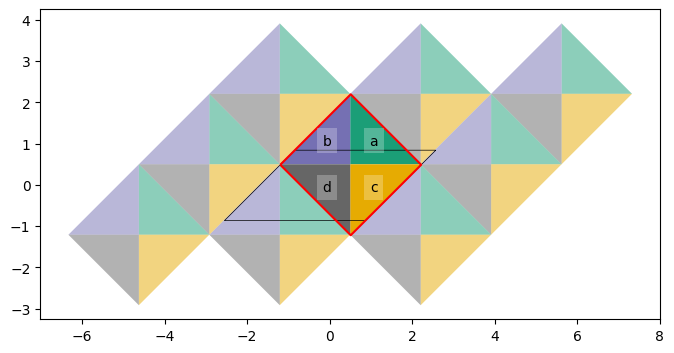

In [6]:
get_tile("t1002", scale = 1, dual = True).plot(r = 1)

In [7]:
def get_tile(code, scale = 50, dual = False):
  mesh = mesh_build(code)
  n = len(mesh.tiles)
  if dual:
    polys = gpd.GeoSeries(
      [geom.Polygon([base_to_point(_product(1/6, xy)) for xy in dual])
                     for dual in mesh.dual_faces])
  else:
    polys = [geom.Polygon([base_to_point(xy)
             for xy in points]) for points in mesh.tiles]
  t = TileUnit()
  t.tiles = gpd.GeoDataFrame(
    geometry = gpd.GeoSeries(polys), crs = 3857,
    data = {"tile_id": tiling_utils.TILE_IDS[:len(polys)]} 
  )
  t.setup_vectors(base_to_point(mesh.tvec1), base_to_point(mesh.tvec2))
  t.prototile = t.get_prototile_from_vectors()
  t._setup_regularised_prototile(override = True)
  return t.transform_scale(scale, scale)

In [8]:
rect = gpd.GeoDataFrame(
  geometry = gpd.GeoSeries(
    [geom.Polygon([(-900, -900), (-900, 900), (900, 900), (900, -900)])]),
  crs = 3857, data = {"x" : [1]}
)

In [9]:
def plot_tiling(code, region = rect):
  unit = get_tile(code, scale = 50)
  dual = get_tile(code, scale = 50, dual = True)
  fig = plt.figure(figsize = (18, 9), layout = "constrained")
  for t, posn in zip([unit, dual], [121, 122]):
    tiling = Tiling(t, rect)
    ax = fig.add_subplot(posn)
    tiling.tiles.plot(ax = ax,
      column = "tile_id", ec = "w", lw = 0.5, cmap = "magma", alpha = 0.75)
    ax.set_title(f"{code}{ '(dual)' if posn == 122 else ''} (n={t.tiles.shape[0]})")
    ax.set_axis_off()
    ax.set_xlim((-720, 720))
    ax.set_ylim((-720, 720))

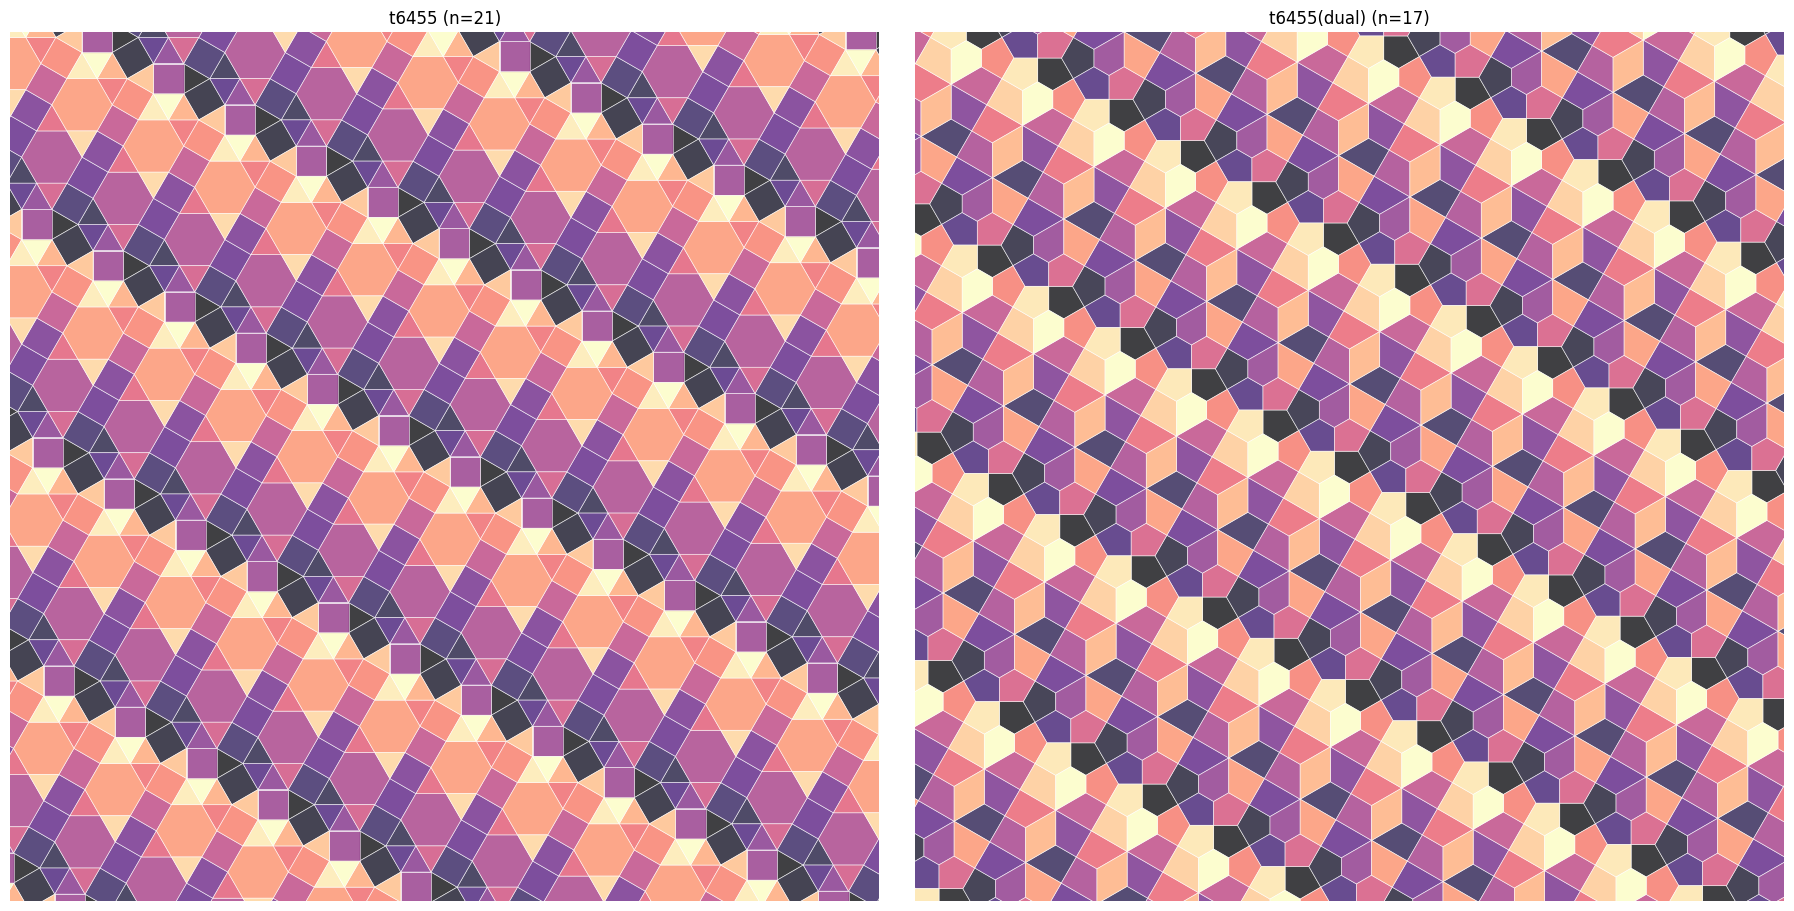

In [12]:
plot_tiling(random.choice(list(Symbols.keys())))